# 06 · Stage 4 small-object strategy: high resolution vs tiling


**Owner:** member C · **GPU:** ≈ 3–5 h · **Needs:** `best_model`, `best_res`, the S1/S2 runs of the best model at 640/960/1280 · **Parallel with:** 05, 07

All rows use the **same 1000-image subset**, so they compare directly with Stage 2:

| Row | Training | Inference | Purpose |
|---|---|---|---|
| Full-frame 640 / 960 / 1280 | full frames | full frame | from Stage 2 (no new training) |
| Naive slicing | full frames @ best res | 640-px native tiles (SAHI-style) | is inference-only slicing enough? (train/test scale mismatch expected) |
| **Tile-trained, sliced** | 640-px native tiles, 20 % overlap | 640-px native tiles | the actual tiling method (Essential) |
| Tile-trained, sliced + full | tiles | tiles + whole frame @1280, merged | helps objects cut by tile borders / large objects |

Merging: class-wise NMS (IoU 0.5) over tile + full-frame detections, max 300 per image. Tiles keep a box if ≥ 30 % of its area is visible;
10 % of empty tiles are kept as negatives. Tile training uses fewer epochs because each frame yields ~18 tiles; the table reports train
hours and latency so accuracy can be judged against compute.

In [ ]:
# ===== 0. Setup — identical in every notebook. Runtime > Change runtime type > T4 GPU =====
SMOKE_TEST = False   # True: 16 train / 8 val images, 1 epoch — checks the whole pipeline in minutes
DRIVE_ROOT = "/content/drive/MyDrive/MAVREC"   # shared team folder (each member: "Add shortcut to Drive")

import os, sys, subprocess, importlib
try:
    from google.colab import drive
    try:
        os.listdir("/content/drive/MyDrive")   # raises if the Drive FUSE mount went stale
        drive.mount("/content/drive")
    except OSError:  # "Transport endpoint is not connected" after a Drive hiccup: remount
        drive.mount("/content/drive", force_remount=True)
except ImportError:
    print("Not in Colab — make sure DRIVE_ROOT exists locally.")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.173", "transformers==5.18.0", "pycocotools>=2.0.8", "timm>=1.0.15", "tabulate", "tensorboard", "seaborn"], check=True)

CODE_DIR = os.path.join(DRIVE_ROOT, "Final_Project_Code")
assert os.path.exists(os.path.join(CODE_DIR, "mavrec_lib.py")), "Run 00_Setup_and_Data_Preparation first (it installs mavrec_lib.py)."
sys.path.insert(0, CODE_DIR)
import mavrec_lib as ml; importlib.reload(ml)
CFG = ml.setup(DRIVE_ROOT, smoke=SMOKE_TEST or None)
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
N_SMALL, N_SCREEN, N_LARGE = ml.TRAIN_SIZES      # 500, 1000, 2000

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Environment:
  python       : 3.13.15
  torch        : 2.11.0+cu130
  cuda         : True
  torchvision  : 0.26.0+cu130
  ultralytics  : 8.4.173
  transformers : 5.18.0
  pycocotools  : 2.0.11
  numpy        : 2.1.3
  lib          : 1.0.0
  gpu          : Tesla T4
  gpu_mem_gb   : 14.6


In [ ]:
BEST_MODEL = ml.get_decision("best_model", required=True)
BEST_RES = ml.get_decision("best_res", required=True)
TILE, OVERLAP = 640, 0.2
TILE_EPOCHS = max(3, round(ml.DEFAULT_EPOCHS[BEST_MODEL] / 5))
df = ml.results_df()
FULL = df[(df.model_version == BEST_MODEL) & (df.dataset_size == N_SCREEN) & (df.tiling == "none") & (df.pretraining == "COCO") &
          df.stage.isin(["S1", "S2"]) & (df.eval_split == "val") & (df.inference_mode == "full")].sort_values("resolution")
BASE = FULL[FULL.resolution == BEST_RES].iloc[0]
print("full-frame reference:", BASE.experiment_id, "| tile epochs:", TILE_EPOCHS)

full-frame reference: S2_yolov8m_n1000_r1280_full_COCO_s42 | tile epochs: 8


### Important · Naive sliced inference with the full-frame model (no training)

In [ ]:
ml.evaluate(BASE.experiment_id, split="val", mode="sliced", res=TILE)

Pack 'aerial_native' unpacked to local disk in 270s
  predicted 538 images (sliced) in 262s, 109030 detections
[S2_yolov8m_n1000_r1280_full_COCO_s42] val|sliced|r640: mAP50-95=27.19 AP50=48.797 APS=23.369 APt=9.044 R=68.47 FPS=2.96


{'mAP50_95': 27.19,
 'mAP50': 48.797,
 'AP75': 25.65,
 'APt': 9.044,
 'APS': 23.369,
 'APM': 29.064,
 'APL': 28.809,
 'AR300': 36.12,
 'mAP50_95_md100': 26.911,
 'APS_md100': 22.743,
 'per_class_AP': {'tram': 0.0,
  'bicycle': 14.205178508913885,
  'van': 26.85485386490552,
  'truck': 76.78501033792476,
  'bus': 0.0,
  'person': 19.827447720813062,
  'car': 46.039540976285224,
  'other': 27.45302696672589,
  'streetlight': 37.540258632081745,
  'traffic_light': 23.199576695298543},
 'per_class_AP50': {'tram': 0.0,
  'bicycle': 41.77626161636326,
  'van': 38.412667312819785,
  'truck': 89.93311819081195,
  'bus': 0.0,
  'person': 55.09266948471648,
  'car': 83.8234967846225,
  'other': 57.403701447808444,
  'streetlight': 70.0101781090225,
  'traffic_light': 51.52044482566135},
 'precision': 78.26,
 'recall': 68.47,
 'F1': 73.038,
 'conf_at_best_f1': 0.4456,
 'latency_ms': 338.19,
 'FPS': 2.96,
 'GPU_memory_infer_GB': 0.29,
 'eval_split': 'val',
 'inference_mode': 'sliced',
 'eval_resol

### Essential · Train on native-resolution tiles, evaluate with sliced inference

In [ ]:
tile_spec = ml.make_spec(BEST_MODEL, f"aerial_train_{N_SCREEN}", stage="S4", tiling="tile_train", tile=TILE, overlap=OVERLAP,
                        epochs=TILE_EPOCHS, full_res=1280, notes=f"{TILE_EPOCHS} epochs on tiles")
ml.run_experiment(tile_spec, eval_modes=["sliced", "sliced+full"])
TILE_ID = tile_spec["experiment_id"]
d = ml.load_json(ml.load_json(os.path.join(CFG["runs_dir"], TILE_ID, "train_info.json"))["train_set_resolved"])
print(f"{len(d['images'])} training tiles from {N_SCREEN} frames")

  tiled 200/1000 frames, 2878 tiles (16s)
  tiled 400/1000 frames, 7533 tiles (43s)
  tiled 600/1000 frames, 11027 tiles (65s)
  tiled 800/1000 frames, 13806 tiles (81s)
  tiled 1000/1000 frames, 15408 tiles (94s)
Tile dataset tiles_aerial_train_1000_t640_o20: 15408 tiles, 131293 boxes from 1000 frames
  uploaded /content/drive/MyDrive/MAVREC/Final_Project_Data/packs/tiles_aerial_train_1000_t640_o20.zip (2.37 GB)
[S4_yolov8m_n1000_r640_tile_COCO_s42] training yolov8m | data=tiles_aerial_train_1000_t640_o20 | res=640 | epochs=8 | batch=16 | init=coco
Pack 'aerial_1280' unpacked to local disk in 70s
New https://pypi.org/project/ultralytics/8.4.175 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, c

## Comparison

,setting,mAP50_95,mAP50,APt,APS,APM,recall,F1,latency_ms,FPS,train_time_h
17,full-frame 640,50.566,73.570,2.059,16.061,47.493,69.730,77.805,20.70,48.31,0.462
13,full-frame 960,61.181,87.426,8.409,29.502,61.990,83.626,87.439,25.72,38.89,0.829
16,full-frame 1280,66.873,91.441,16.537,38.394,66.810,89.438,90.852,32.99,30.31,1.531
17,naive slicing (full-frame model),27.190,48.797,9.044,23.369,29.064,68.470,73.038,338.19,2.96,1.531
20,"tile-trained, sliced",57.912,90.819,23.167,46.818,55.193,92.545,92.936,337.79,2.96,0.949
21,"tile-trained, sliced+full",56.249,90.612,22.423,45.264,54.967,90.423,91.125,407.86,2.45,0.949


saved /content/drive/MyDrive/MAVREC/Final_Project_Results/tables/S4_tiling.csv
saved /content/drive/MyDrive/MAVREC/Final_Project_Results/figures/S4_tiling.png


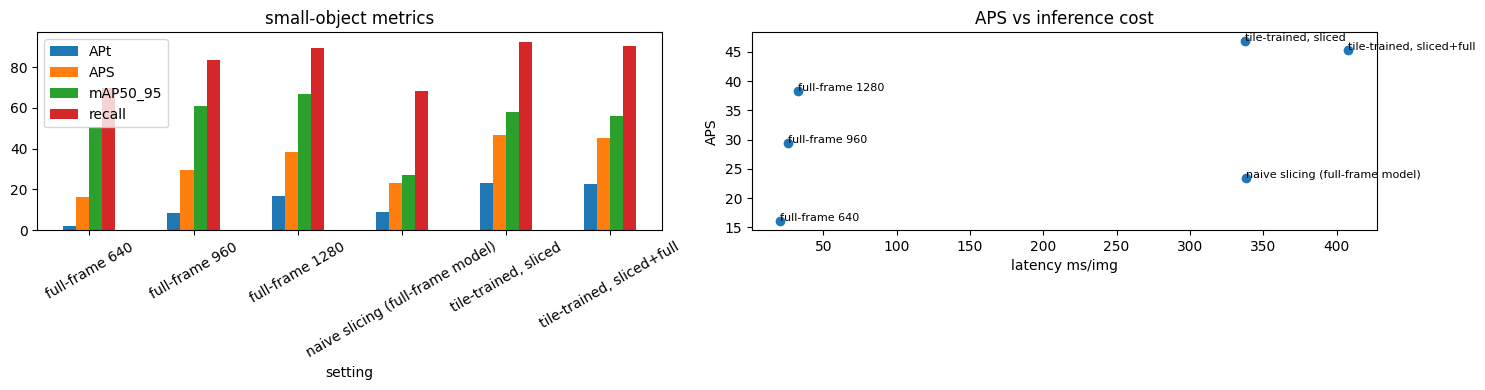

In [ ]:
df = ml.results_df()
T = pd.concat([FULL, df[(df.experiment_id == BASE.experiment_id) & (df.inference_mode == "sliced")],
               df[(df.experiment_id == TILE_ID) & (df.eval_split == "val")]])
T["setting"] = [("full-frame " + str(int(r.resolution))) if r.inference_mode == "full" else
                ("naive slicing (full-frame model)" if r.tiling == "none" else f"tile-trained, {r.inference_mode}") for r in T.itertuples()]
cols = ["setting", "mAP50_95", "mAP50", "APt", "APS", "APM", "recall", "F1", "latency_ms", "FPS", "train_time_h"]
display(T[cols])
ml.save_table(T[cols], "S4_tiling")
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
T.set_index("setting")[["APt", "APS", "mAP50_95", "recall"]].plot.bar(ax=ax[0]); ax[0].set_title("small-object metrics"); ax[0].tick_params(axis="x", rotation=30)
ax[1].scatter(T.latency_ms, T.APS)
for r in T.itertuples(): ax[1].annotate(r.setting, (r.latency_ms, r.APS), fontsize=8)
ax[1].set_xlabel("latency ms/img"); ax[1].set_ylabel("APS"); ax[1].set_title("APS vs inference cost")
plt.tight_layout(); ml.savefig("S4_tiling.png"); plt.show()

## Objects missed by full-frame but recovered by tiling (qualitative figure for the report)

In [ ]:
tbest = T[T.tiling == "tile_train"].sort_values("APS", na_position="first").iloc[-1]
full_best = T[T.inference_mode == "full"].sort_values("APS", na_position="first").iloc[-1]
rec = ml.recovered_objects("aerial_val", full_best.preds_path, full_best.conf_at_best_f1 or 0.25, tbest.preds_path, tbest.conf_at_best_f1 or 0.25)
print(f"recovered by tiling: {len(rec['recovered'])} objects; lost by tiling: {len(rec['lost'])}")
sizes = pd.Series([np.sqrt(a["area"]) for a in rec["recovered"]])
print("recovered object size (sqrt area, native px):", sizes.describe().round(1).to_dict())
for img_id, n in rec["per_image"][:2]:
    ml.show_recovered("aerial_val", "aerial_native", rec["recovered"], img_id, out_path=os.path.join(CFG["figures_dir"], f"S4_recovered_{img_id}.png"),
                      title=f"{n} objects found by tiling but missed by {full_best.setting} (green)")
ml.prediction_grid([(full_best.setting, full_best.preds_path, full_best.conf_at_best_f1), (tbest.setting, tbest.preds_path, tbest.conf_at_best_f1)],
                   "aerial_val", "aerial_native", image_ids=[i for i, _ in rec["per_image"][:2]], out_path=os.path.join(CFG["figures_dir"], "S4_grid.png"))

## Decision: does tiling earn its place in the final model?

In [ ]:
g = ml.component_gain(BASE, tbest)
print(g)
ml.set_decision("use_tiling", g["keep"], f"{tbest.setting} vs full-frame {BEST_RES}: {g}")
ml.set_decision("tiling_mode", tbest.inference_mode, "best tile-trained inference mode on val (APS)")